# Decision Tree **Classifier**

## Task 1: Import the required libraries

In [3]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

# Task 2: Load the dataset and read its description

In [4]:
iris_df = pd.read_csv("Iris.csv")

print("Shape:", iris_df.shape)
print("Columns:", iris_df.columns.tolist())
display(iris_df.head())

print("\nColumn information:")
iris_df.info()

print("\nDescriptive statistics:")
display(iris_df.describe())

print("\nMissing values:", int(iris_df.isnull().sum().sum()))
print("Duplicate rows :", int(iris_df.duplicated().sum()))

Shape: (150, 6)
Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Descriptive statistics:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000



Missing values: 0
Duplicate rows : 0


In [6]:
iris_df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [18]:
print("Shape:", iris_df.shape)

Shape: (150, 6)


# Task 3: Inspect the target variable

In [19]:
print("Species value counts:")
print(iris_df["Species"].value_counts().to_string())

print("\nDistinct species:", iris_df["Species"].unique().tolist())
print("Data type of the target column:", iris_df["Species"].dtype)

Species value counts:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50

Distinct species: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Data type of the target column: object


# Task 4: Create the independent features (X)

In [20]:
X = iris_df.drop(columns=["Id", "Species"])

print("Feature columns:", X.columns.tolist())
print("Shape of X:", X.shape)
display(X.head())
display(X.describe().round(2))

Feature columns: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Shape of X: (150, 4)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [8]:
y = iris_df["Species"]
y

0         Iris-setosa
1         Iris-setosa
2         Iris-setosa
3         Iris-setosa
4         Iris-setosa
            ...      
145    Iris-virginica
146    Iris-virginica
147    Iris-virginica
148    Iris-virginica
149    Iris-virginica
Name: Species, Length: 150, dtype: object

# Task 5: Create the dependent feature (y)

In [21]:
encoder=LabelEncoder()
y=encoder.fit_transform(y)
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

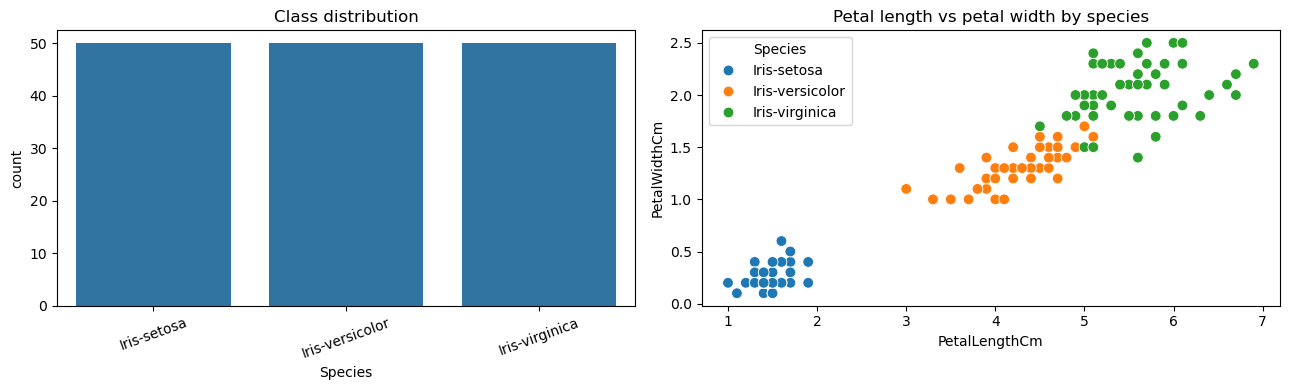

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=iris_df["Species"], ax=axes[0])
axes[0].set_title("Class distribution")
axes[0].tick_params(axis="x", rotation=20)

sns.scatterplot(x=X["PetalLengthCm"], y=X["PetalWidthCm"],
                hue=iris_df["Species"], s=60, ax=axes[1])
axes[1].set_title("Petal length vs petal width by species")
plt.tight_layout()
plt.show()

# Task 6: Train/test split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10
)

print("Training observations:", X_train.shape[0])
print("Testing observations :", X_test.shape[0])

Training observations: 120
Testing observations : 30


# Task 7: Apply the Decision Tree Classifier

In [61]:
treeclassifier = DecisionTreeClassifier(random_state=10)
treeclassifier.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully.")
print("Depth of the fitted tree :", treeclassifier.get_depth())
print("Number of leaves         :", treeclassifier.get_n_leaves())

Decision Tree Classifier trained successfully.
Depth of the fitted tree : 6
Number of leaves         : 10


# Task 8: Visualise the decision tree

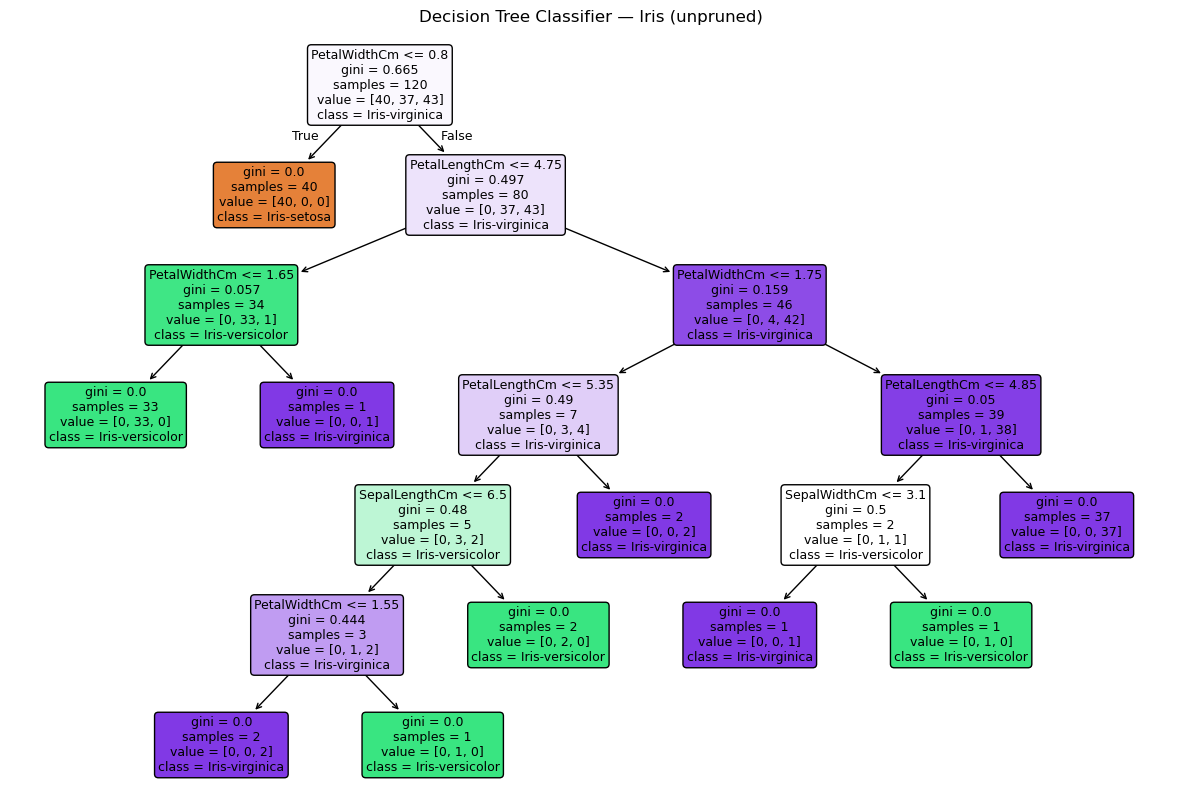

The same tree written as text rules:

|--- PetalWidthCm <= 0.80
|   |--- class: 0
|--- PetalWidthCm >  0.80
|   |--- PetalLengthCm <= 4.75
|   |   |--- PetalWidthCm <= 1.65
|   |   |   |--- class: 1
|   |   |--- PetalWidthCm >  1.65
|   |   |   |--- class: 2
|   |--- PetalLengthCm >  4.75
|   |   |--- PetalWidthCm <= 1.75
|   |   |   |--- PetalLengthCm <= 5.35
|   |   |   |   |--- SepalLengthCm <= 6.50
|   |   |   |   |   |--- PetalWidthCm <= 1.55
|   |   |   |   |   |   |--- class: 2
|   |   |   |   |   |--- PetalWidthCm >  1.55
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- SepalLengthCm >  6.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- PetalLengthCm >  5.35
|   |   |   |   |--- class: 2
|   |   |--- PetalWidthCm >  1.75
|   |   |   |--- PetalLengthCm <= 4.85
|   |   |   |   |--- SepalWidthCm <= 3.10
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- SepalWidthCm >  3.10
|   |   |   |   |   |--- class: 1
|   |   |   |--- PetalLengthCm >  4.85
|   |   |   |   

In [62]:
plt.figure(figsize=(15, 10))
tree.plot_tree(treeclassifier, filled=True, rounded=True,
               feature_names=X.columns, class_names=target_names, fontsize=9)
plt.title("Decision Tree Classifier — Iris (unpruned)")
plt.show()

print("The same tree written as text rules:\n")
print(export_text(treeclassifier, feature_names=list(X.columns)))

# Task 9: Predict on the test data

In [63]:
y_pred = treeclassifier.predict(X_test)

print("Predicted labels:")
print(y_pred)

print("\nActual labels:")
print(y_test)

Predicted labels:
[1 2 0 1 0 1 2 1 0 1 1 2 1 0 0 2 1 0 0 0 2 2 2 0 1 0 1 1 1 2]

Actual labels:
[1 2 0 1 0 1 1 1 0 1 1 2 1 0 0 2 1 0 0 0 2 2 2 0 1 0 1 1 1 2]


# Task 10: Evaluate with a confusion matrix and classification report

Confusion matrix:
[[10  0  0]
 [ 0 12  1]
 [ 0  0  7]]

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.92      0.96        13
 Iris-virginica       0.88      1.00      0.93         7

       accuracy                           0.97        30
      macro avg       0.96      0.97      0.96        30
   weighted avg       0.97      0.97      0.97        30

Accuracy: 0.9667  (96.67%)


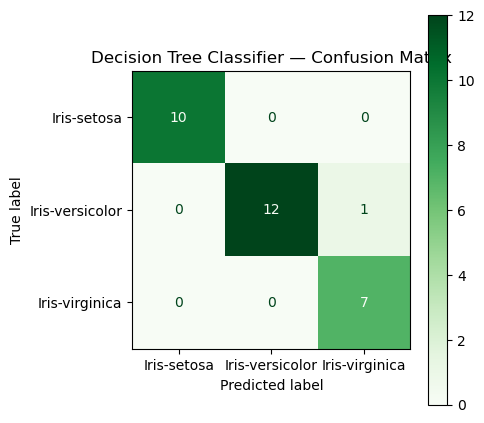

In [64]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:")
print(cm)
print()
print(classification_report(y_test, y_pred, target_names=target_names))

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}  ({accuracy * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=target_names).plot(ax=ax, cmap="Greens")
ax.set_title("Decision Tree Classifier — Confusion Matrix")
plt.tight_layout()
plt.show()

In [52]:
treeclassifier = DecisionTreeClassifier(random_state=10,max_depth=2)
treeclassifier.fit(X_train, y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,10
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


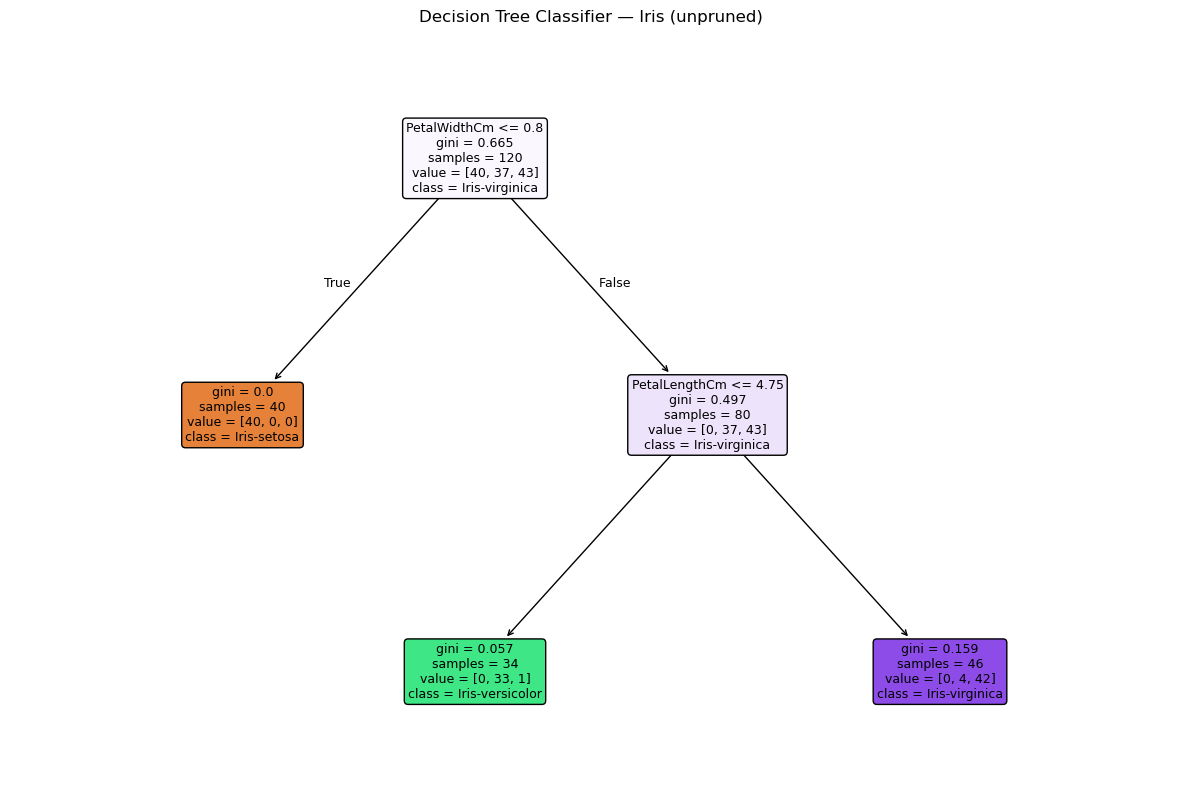

The same tree written as text rules:

|--- PetalWidthCm <= 0.80
|   |--- class: 0
|--- PetalWidthCm >  0.80
|   |--- PetalLengthCm <= 4.75
|   |   |--- class: 1
|   |--- PetalLengthCm >  4.75
|   |   |--- class: 2



In [53]:
plt.figure(figsize=(15, 10))
tree.plot_tree(treeclassifier, filled=True, rounded=True,
               feature_names=X.columns, class_names=target_names, fontsize=9)
plt.title("Decision Tree Classifier — Iris (unpruned)")
plt.show()

print("The same tree written as text rules:\n")
print(export_text(treeclassifier, feature_names=list(X.columns)))

# Task 11: Detect overfitting

In [16]:
train_acc = accuracy_score(y_train, treeclassifier.predict(X_train))
test_acc  = accuracy_score(y_test, y_pred)

print(f"Training accuracy : {train_acc:.4f}")
print(f"Testing accuracy  : {test_acc:.4f}")
print(f"Gap               : {train_acc - test_acc:.4f}")
print(f"\nTree depth: {treeclassifier.get_depth()}   Leaves: {treeclassifier.get_n_leaves()}")

Training accuracy : 1.0000
Testing accuracy  : 0.9667
Gap               : 0.0333

Tree depth: 6   Leaves: 10


# Task 12: Pre-pruning: study the effect of tree depth

,max_depth,train_accuracy,test_accuracy,leaves
0,1,0.6917,0.5667,2
1,2,0.9583,0.9333,3
2,3,0.9667,0.9333,5
3,4,0.9750,0.9667,7
4,5,0.9917,0.9667,9
5,6,1.0000,0.9667,10
6,7,1.0000,0.9667,10
7,8,1.0000,0.9667,10
8,9,1.0000,0.9667,10
9,10,1.0000,0.9667,10


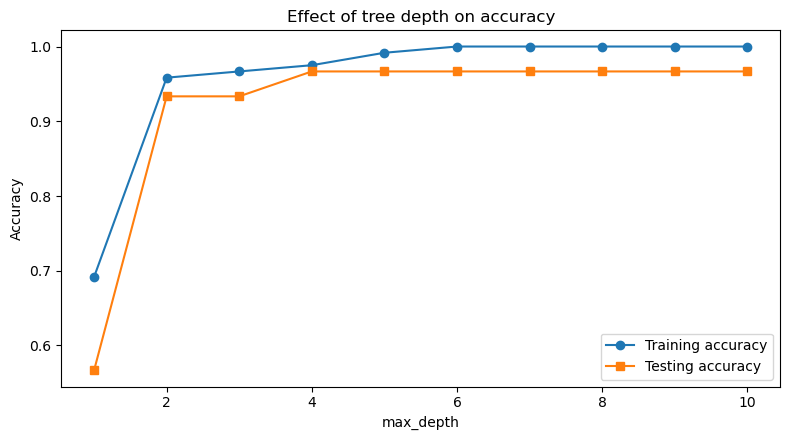

In [17]:
rows = []
for depth in range(1, 11):
    m = DecisionTreeClassifier(max_depth=depth, random_state=10).fit(X_train, y_train)
    rows.append({
        "max_depth": depth,
        "train_accuracy": accuracy_score(y_train, m.predict(X_train)),
        "test_accuracy":  accuracy_score(y_test, m.predict(X_test)),
        "leaves": m.get_n_leaves(),
    })

depth_df = pd.DataFrame(rows)
display(depth_df.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(depth_df["max_depth"], depth_df["train_accuracy"], marker="o", label="Training accuracy")
plt.plot(depth_df["max_depth"], depth_df["test_accuracy"],  marker="s", label="Testing accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Effect of tree depth on accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Task 13: Pre-pruning and hyperparameter tuning with GridSearchCV

In [48]:
param = {
    "criterion":    ["gini", "entropy", "log_loss"],
    "splitter":     ["best", "random"],
    "max_depth":    [1, 2, 3, 4, 5],
    "max_features": ["sqrt", "log2", None],   # 'auto' was REMOVED in scikit-learn 1.3
}
print("Parameter grid:")
for k, v in param.items():
    print(f"   {k}: {v}")

treemodel = DecisionTreeClassifier(random_state=10)
grid = GridSearchCV(treemodel, param_grid=param, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("\nBest parameters found:")
for k, v in grid.best_params_.items():
    print(f"   {k}: {v}")
print(f"\nBest cross-validated accuracy: {grid.best_score_:.4f}")


Best parameters found:
   criterion: entropy
   max_depth: 4
   max_features: None
   splitter: random

Best cross-validated accuracy: 0.9500


# Task 14: Evaluate the tuned model

In [49]:
y_pred_grid = grid.predict(X_test)
print("Predictions from the tuned model:")
print(y_pred_grid)

cm_grid = confusion_matrix(y_test, y_pred_grid)
print("\nConfusion matrix:")
print(cm_grid)
print()
print(classification_report(y_test, y_pred_grid, target_names=iris["target_names"]))

score = accuracy_score(y_test, y_pred_grid)
print(f"Accuracy of the tuned model: {score:.4f}  ({score * 100:.2f}%)")

comparison = pd.DataFrame([
    {"Model": "Default (unpruned)",
     "Train": accuracy_score(y_train, treeclassifier.predict(X_train)),
     "Test":  accuracy_score(y_test, y_pred),
     "Leaves": treeclassifier.get_n_leaves()},
    {"Model": "GridSearchCV best",
     "Train": accuracy_score(y_train, grid.predict(X_train)),
     "Test":  score,
     "Leaves": grid.best_estimator_.get_n_leaves()},
])
display(comparison.round(4))

Predictions from the tuned model:
[1 2 0 1 0 1 1 1 0 1 1 2 1 0 0 2 1 0 0 0 2 2 1 0 1 0 1 1 1 2]

Confusion matrix:
[[10  0  0]
 [ 0 13  0]
 [ 0  1  6]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.93      1.00      0.96        13
   virginica       1.00      0.86      0.92         7

    accuracy                           0.97        30
   macro avg       0.98      0.95      0.96        30
weighted avg       0.97      0.97      0.97        30

Accuracy of the tuned model: 0.9667  (96.67%)


,Model,Train,Test,Leaves
0,Default (unpruned),1.0000,0.9667,10
1,GridSearchCV best,0.9417,0.9667,6


# Task 15: Feature importance

,feature,importance
2,PetalLengthCm,0.897
3,PetalWidthCm,0.103
0,SepalLengthCm,0.000
1,SepalWidthCm,0.000


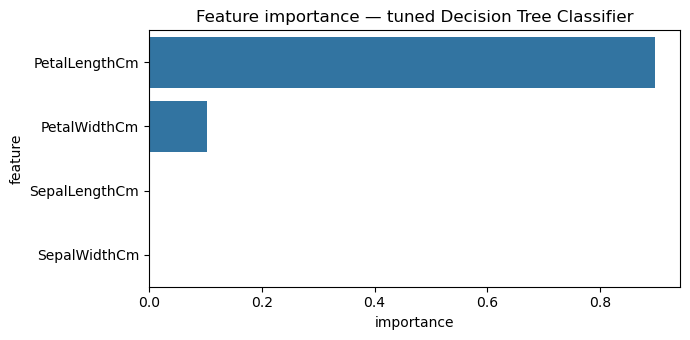

The importances sum to: 1.0


In [50]:
best_model = grid.best_estimator_

importance = pd.DataFrame({
    "feature": X.columns,
    "importance": best_model.feature_importances_,
}).sort_values("importance", ascending=False)
display(importance.round(4))

plt.figure(figsize=(7, 3.5))
sns.barplot(data=importance, x="importance", y="feature")
plt.title("Feature importance — tuned Decision Tree Classifier")
plt.tight_layout()
plt.show()

print("The importances sum to:", round(importance["importance"].sum(), 4))

# Task 16: Predict a new, unseen flower

In [51]:
new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2],
                           [6.7, 3.0, 5.2, 2.3]], columns=X.columns)
display(new_flower)

preds  = best_model.predict(new_flower)
probas = best_model.predict_proba(new_flower)

for i, (p, pr) in enumerate(zip(preds, probas)):
    probs = {str(n): float(v) for n, v in zip(iris["target_names"], pr.round(3))}
    print(f"Flower {i + 1}: predicted = {iris['target_names'][p]}   probabilities = {probs}")

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,6.7,3.0,5.2,2.3


Flower 1: predicted = setosa   probabilities = {'setosa': 1.0, 'versicolor': 0.0, 'virginica': 0.0}
Flower 2: predicted = virginica   probabilities = {'setosa': 0.0, 'versicolor': 0.0, 'virginica': 1.0}
